# Restaurant Rating Prediction

An end-to-end regression workflow using the provided restaurant dataset. Run the cells from top to bottom. The target is `Aggregate rating`; unrated rows (rating 0 / `Not rated`) are excluded. The Streamlit UI is in `app.py` and uses the artifacts created near the end of this notebook.

## 1. Setup and data collection

The CSV already in this project folder is the data source. Install dependencies with `pip install -r requirements.txt` if needed.

In [2]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
ROOT = Path.cwd()
DATA_PATH = ROOT / 'Dataset .csv'
MODEL_PATH = ROOT / 'restaurant_rating_model.joblib'
METADATA_PATH = ROOT / 'restaurant_rating_metadata.json'

FEATURES = [
    'City', 'Locality', 'Average Cost for two', 'Currency',
    'Has Table booking', 'Has Online delivery', 'Cuisines'
]
TARGET = 'Aggregate rating'
NUMERIC_FEATURES = ['Average Cost for two']
CATEGORICAL_FEATURES = [feature for feature in FEATURES if feature not in NUMERIC_FEATURES]
print(f'Workspace: {ROOT}')
print(f'Dataset found: {DATA_PATH.is_file()} ({DATA_PATH})')

Workspace: c:\Users\Jamshaid Mustafa\OneDrive\ahmed mustafa 2.0\New folder
Dataset found: True (c:\Users\Jamshaid Mustafa\OneDrive\ahmed mustafa 2.0\New folder\Dataset .csv)


In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Could not find {DATA_PATH}. Keep the CSV beside this notebook.')

raw_df = pd.read_csv(DATA_PATH)
print(f'Loaded {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns.')
display(raw_df.head())
display(pd.DataFrame({'column': raw_df.columns, 'dtype': raw_df.dtypes.astype(str).values}))

Loaded 9,551 rows and 21 columns.


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


,column,dtype
0,Restaurant ID,int64
1,Restaurant Name,object
2,Country Code,int64
3,City,object
4,Address,object
5,Locality,object
6,Locality Verbose,object
7,Longitude,float64
8,Latitude,float64
9,Cuisines,object


## 2. Data cleaning

Keep only the seven selected predictors. Exclude unrated restaurants: in this dataset their numeric rating is 0 and their rating text is `Not rated`, so 0 is not a real rating. Do not feed `Rating text` or `Rating color` into the model because they are derived from the target.

In [4]:
required_columns = FEATURES + [TARGET, 'Rating text']
missing_columns = sorted(set(required_columns) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f'Dataset is missing required columns: {missing_columns}')

df = raw_df[required_columns].copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
df['Average Cost for two'] = pd.to_numeric(df['Average Cost for two'], errors='coerce')
df = df.dropna(subset=[TARGET])
df = df[(df[TARGET] > 0) & (df['Rating text'].fillna('').str.casefold() != 'not rated')]
df = df.drop(columns=['Rating text']).drop_duplicates().reset_index(drop=True)

for column in CATEGORICAL_FEATURES:
    df[column] = df[column].fillna('Unknown').astype(str).str.strip()
    df.loc[df[column].eq(''), column] = 'Unknown'
df['Average Cost for two'] = df['Average Cost for two'].replace([np.inf, -np.inf], np.nan)
if df.empty:
    raise ValueError('No rated rows remain after data cleaning.')

print(f'Rows available for modeling: {len(df):,}')
print(f'Removed unrated/invalid rows: {len(raw_df) - len(df):,}')
display(df.isna().sum().rename('missing values').to_frame())
display(df[TARGET].describe().to_frame().T)

Rows available for modeling: 7,377
Removed unrated/invalid rows: 2,174


,missing values
City,0
Locality,0
Average Cost for two,0
Currency,0
Has Table booking,0
Has Online delivery,0
Cuisines,0
Aggregate rating,0


,count,mean,std,min,25%,50%,75%,max
Aggregate rating,7377.0,3.440992,0.552516,1.8,3.0,3.4,3.8,4.9


## 3. Exploratory data analysis (EDA)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,7377,141,New Delhi,4034,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality,7377,1175,Connaught Place,119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Average Cost for two,7377.0,NaN,NaN,NaN,1452.403009,18335.627885,0.0,300.0,500.0,800.0,800000.0
Currency,7377,12,Indian Rupees(Rs.),6491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Has Table booking,7377,2,No,6266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Has Online delivery,7377,2,No,5026,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cuisines,7377,1716,North Indian,487,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Aggregate rating,7377.0,NaN,NaN,NaN,3.440992,0.552516,1.8,3.0,3.4,3.8,4.9


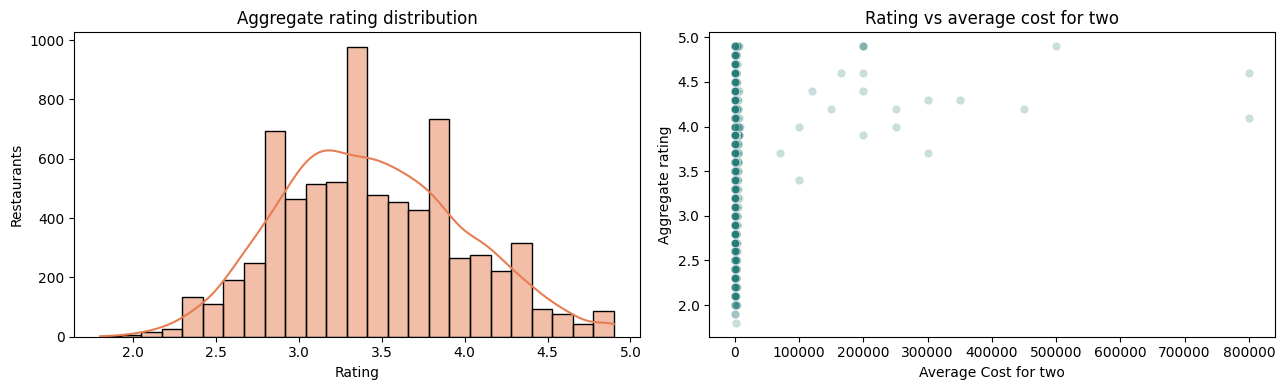

,count,mean
City,,
New Delhi,4034,3.298166
Gurgaon,886,3.331603
Noida,693,3.161039
Faridabad,151,3.103311
Ghaziabad,23,3.100000
Bhubaneshwar,21,3.980952
Lucknow,21,4.195238
Guwahati,21,4.190476
Ahmedabad,21,4.161905


In [5]:
display(df[FEATURES + [TARGET]].describe(include='all').T)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], bins=25, kde=True, ax=axes[0], color='#e67e52')
axes[0].set(title='Aggregate rating distribution', xlabel='Rating', ylabel='Restaurants')
sns.scatterplot(data=df, x='Average Cost for two', y=TARGET, alpha=0.25, ax=axes[1], color='#287c78')
axes[1].set(title='Rating vs average cost for two')
plt.tight_layout()
plt.show()

display(df.groupby('City', dropna=False)[TARGET].agg(['count', 'mean']).sort_values('count', ascending=False).head(15))

## 4. Feature engineering and train/test split

The selected fields are retained as predictors; missing numeric costs are imputed, and text/category values are normalized. Cuisine is represented as a categorical value. The split happens before the preprocessing pipeline is fitted to prevent information leakage.

In [6]:
X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f'Train rows: {len(X_train):,}; test rows: {len(X_test):,}')
print(f'Numeric features: {NUMERIC_FEATURES}')
print(f'Categorical features: {CATEGORICAL_FEATURES}')

Train rows: 5,901; test rows: 1,476
Numeric features: ['Average Cost for two']
Categorical features: ['City', 'Locality', 'Currency', 'Has Table booking', 'Has Online delivery', 'Cuisines']


## 5. Feature scaling and preprocessing

Numeric cost is imputed with the training median and standardized. Categorical fields are imputed and one-hot encoded; rare categories are grouped to control the high cardinality of locality and cuisine.

In [7]:
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False)),
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=5)),
])
preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, NUMERIC_FEATURES),
    ('categorical', categorical_pipeline, CATEGORICAL_FEATURES),
])
print('Preprocessing pipeline configured.')

Preprocessing pipeline configured.


## 6. Model selection and training

Compare a mean-prediction baseline with Ridge regression and Extra Trees. All models share the same preprocessing pipeline.

In [8]:
candidate_models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Ridge regression': Ridge(alpha=10.0),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=160, min_samples_leaf=2, max_features=0.8,
        n_jobs=-1, random_state=RANDOM_STATE
    ),
}
comparison_rows = []
for model_name, estimator in candidate_models.items():
    candidate = Pipeline(steps=[('preprocessor', preprocessor), ('model', estimator)])
    cv_scores = cross_val_score(
        candidate, X_train, y_train, cv=3,
        scoring='neg_mean_absolute_error', n_jobs=1
    )
    comparison_rows.append({
        'model': model_name,
        'CV MAE': -float(cv_scores.mean()),
        'CV MAE std': float(cv_scores.std()),
    })
comparison = pd.DataFrame(comparison_rows).sort_values('CV MAE').reset_index(drop=True)
display(comparison)
best_initial_name = comparison.loc[0, 'model']
print(f'Best initial model by training cross-validation MAE: {best_initial_name}')

,model,CV MAE,CV MAE std
0,Ridge regression,0.309066,0.000771
1,Extra Trees,0.329862,0.006157
2,Mean baseline,0.450041,0.001037


Best initial model by training cross-validation MAE: Ridge regression


## 7. Hyperparameter tuning

Tune the two practical candidates with cross-validation on the training split only. The held-out test set remains reserved for the final evaluation.

In [9]:
tuning_candidates = []
ridge_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', Ridge())])
ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={'model__alpha': [1.0, 10.0, 50.0]},
    scoring='neg_mean_absolute_error', cv=3, n_jobs=-1, refit=True,
)
ridge_search.fit(X_train, y_train)
tuning_candidates.append(('Ridge regression', ridge_search))

trees_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', ExtraTreesRegressor(
        n_estimators=160, n_jobs=-1, random_state=RANDOM_STATE
    )),
])
trees_search = GridSearchCV(
    trees_pipeline,
    param_grid={
        'model__min_samples_leaf': [2, 5],
        'model__max_features': [0.6, 1.0],
    },
    scoring='neg_mean_absolute_error', cv=3, n_jobs=1, refit=True,
)
trees_search.fit(X_train, y_train)
tuning_candidates.append(('Extra Trees', trees_search))

tuning_results = pd.DataFrame([
    {
        'model': name,
        'best_cv_mae': -search.best_score_,
        'best_parameters': search.best_params_,
    }
    for name, search in tuning_candidates
]).sort_values('best_cv_mae').reset_index(drop=True)
display(tuning_results)
best_name, best_search = min(tuning_candidates, key=lambda item: -item[1].best_score_)
final_model = best_search.best_estimator_
print(f'Selected model: {best_name}; parameters: {best_search.best_params_}')

,model,best_cv_mae,best_parameters
0,Ridge regression,0.305212,{'model__alpha': 1.0}
1,Extra Trees,0.323113,"{'model__max_features': 0.6, 'model__min_sampl..."


Selected model: Ridge regression; parameters: {'model__alpha': 1.0}


## 8. Final model evaluation

Evaluate the selected, tuned pipeline once on the held-out test set. MAE and RMSE are in rating points; R² is a goodness-of-fit measure.

,test metric
MAE,0.302259
RMSE,0.392299
R2,0.490652


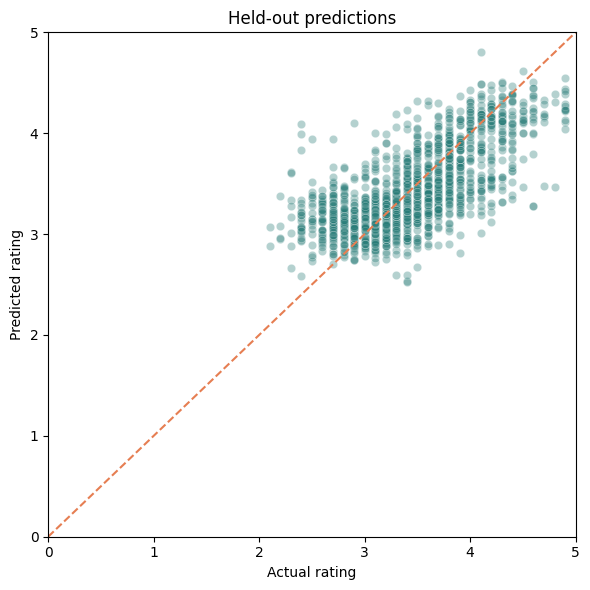

In [10]:
test_predictions = final_model.predict(X_test)
test_mae = float(mean_absolute_error(y_test, test_predictions))
test_rmse = float(np.sqrt(mean_squared_error(y_test, test_predictions)))
test_r2 = float(r2_score(y_test, test_predictions))
final_metrics = {'MAE': test_mae, 'RMSE': test_rmse, 'R2': test_r2}
display(pd.Series(final_metrics, name='test metric').to_frame())

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(x=y_test, y=test_predictions, alpha=0.35, ax=ax, color='#287c78')
ax.plot([0, 5], [0, 5], '--', color='#e67e52')
ax.set(xlim=(0, 5), ylim=(0, 5), xlabel='Actual rating', ylabel='Predicted rating', title='Held-out predictions')
plt.tight_layout()
plt.show()

## 9. Save the complete model

The fitted sklearn pipeline includes preprocessing and the estimator, so the UI can send raw feature values. Metadata supplies sensible options to the form.

In [12]:
joblib.dump(final_model, MODEL_PATH)
metadata = {
    'feature_columns': FEATURES,
    'training_rows': int(len(X_train)),
    'test_mae': test_mae,
    'test_rmse': test_rmse,
    'test_r2': test_r2,
    'selected_model': best_name,
    'cities': sorted(df['City'].unique().tolist()),
    'localities': sorted(df['Locality'].unique().tolist()),
    'currencies': sorted(df['Currency'].unique().tolist()),
    'booking_options': sorted(df['Has Table booking'].unique().tolist()),
    'delivery_options': sorted(df['Has Online delivery'].unique().tolist()),
    'cuisines': sorted(df['Cuisines'].unique().tolist()),
    'median_cost': float(df['Average Cost for two'].median()),
    'max_cost': float(max(df['Average Cost for two'].max(), 1.0)),
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print(f'Saved model: {MODEL_PATH}')
print(f'Saved UI metadata: {METADATA_PATH}')

Saved model: c:\Users\Jamshaid Mustafa\OneDrive\ahmed mustafa 2.0\New folder\restaurant_rating_model.joblib
Saved UI metadata: c:\Users\Jamshaid Mustafa\OneDrive\ahmed mustafa 2.0\New folder\restaurant_rating_metadata.json


## 10. FastAPI prediction API (defined in this notebook)

This cell defines the API object and request schema. The next cell starts the API asynchronously from this notebook kernel. The requested Streamlit frontend is started separately with `streamlit run app.py`.

In [13]:
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

api = FastAPI(title='Restaurant Rating Predictor API', version='1.0.0')

class RestaurantFeatures(BaseModel):
    city: str = Field(min_length=1)
    locality: str = Field(min_length=1)
    average_cost_for_two: float = Field(ge=0)
    currency: str = Field(min_length=1)
    has_table_booking: str = Field(min_length=1)
    has_online_delivery: str = Field(min_length=1)
    cuisine: str = Field(min_length=1)

@api.get('/health')
def health_check():
    return {'status': 'ok', 'model_loaded': MODEL_PATH.is_file()}

@api.post('/predict')
def predict_rating(features: RestaurantFeatures):
    values = pd.DataFrame([{
        'City': features.city,
        'Locality': features.locality,
        'Average Cost for two': features.average_cost_for_two,
        'Currency': features.currency,
        'Has Table booking': features.has_table_booking,
        'Has Online delivery': features.has_online_delivery,
        'Cuisines': features.cuisine,
    }], columns=FEATURES)
    try:
        score = float(final_model.predict(values)[0])
    except (ValueError, TypeError, KeyError) as exc:
        raise HTTPException(status_code=422, detail=str(exc)) from exc
    return {'predicted_rating': round(float(np.clip(score, 0.0, 5.0)), 2)}

app = api
print('FastAPI application is available as `app` (API object) / `api`.')

FastAPI application is available as `app` (API object) / `api`.


In [14]:
import uvicorn

# Run this cell when you want to serve the API; interrupt it to stop the server.
server = uvicorn.Server(uvicorn.Config(api, host='127.0.0.1', port=8000))
await server.serve()

INFO:     Started server process [33656]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:62894 - "GET / HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:62894 - "GET /favicon.ico HTTP/1.1" 404 Not Found


INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [33656]
